In [10]:
import pandas as pd
import numpy as np
pd.options.display.max_columns = 100
import seaborn as sns
import matplotlib.pyplot as plt

In [11]:
penguins = sns.load_dataset('penguins')
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [12]:
penguins.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='str')

# Task 1: Data Preprocessing Overview

Create three separate datasets to follow the required geometric constraints.

1. For the Euclidean dataset (penguins_cont), select only the continuous columns: bill_length_mm, bill_depth_mm, flipper_length_mm, and body_mass_g. Since K-Means relies on spatial magnitude, use a StandardScaler to make sure body_mass_g does not dominate the millimetre-based features.

2. For the categorical dataset (penguins_cat), select only the categorical columns: species, island, and sex. Do not apply scaling or One-Hot Encoding to this data.

3. For the mixed-data dataset (penguins_mixed), include all columns. 


In [13]:
from sklearn.preprocessing import StandardScaler

continuous_features = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]
categorical_features = ['species', 'island', 'sex']

# Use the same complete rows for every clustering method.
penguins_clean = penguins.dropna().copy()

scaler = StandardScaler()
penguins_cont = pd.DataFrame(
    scaler.fit_transform(penguins_clean[continuous_features]),
    columns=continuous_features,
    index=penguins_clean.index
)
penguins_cat = penguins_clean[categorical_features].copy()
penguins_mixed = penguins_clean.copy()
penguins_mixed[continuous_features] = penguins_cont
penguins_mixed[categorical_features] = penguins_mixed[categorical_features].astype(object)

print(f'Rows retained after removing missing values: {len(penguins_clean)}')
display(penguins_cont.head())
display(penguins_cat.head())
display(penguins_mixed.head())

Rows retained after removing missing values: 333


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.896042,0.780732,-1.426752,-0.568475
1,-0.822788,0.119584,-1.069474,-0.506286
2,-0.676280,0.424729,-0.426373,-1.190361
4,-1.335566,1.085877,-0.569284,-0.941606
5,-0.859415,1.747026,-0.783651,-0.692852


,species,island,sex
0,Adelie,Torgersen,Male
1,Adelie,Torgersen,Female
2,Adelie,Torgersen,Female
4,Adelie,Torgersen,Female
5,Adelie,Torgersen,Male


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,-0.896042,0.780732,-1.426752,-0.568475,Male
1,Adelie,Torgersen,-0.822788,0.119584,-1.069474,-0.506286,Female
2,Adelie,Torgersen,-0.676280,0.424729,-0.426373,-1.190361,Female
4,Adelie,Torgersen,-1.335566,1.085877,-0.569284,-0.941606,Female
5,Adelie,Torgersen,-0.859415,1.747026,-0.783651,-0.692852,Male


# Task 2: The Euclidean Baseline (K-Means)

Let's start by ignoring penguins' species, sex, and location and focus solely on clustering by their physical measurements.

1. Train a `KMeans` model using your scaled `penguins_cont` dataset. Then use the Elbow Method to determine the best value for K.

2. Calculate the standard Euclidean Silhouette Score.

3. Create a visualisation and analyse the clusters.

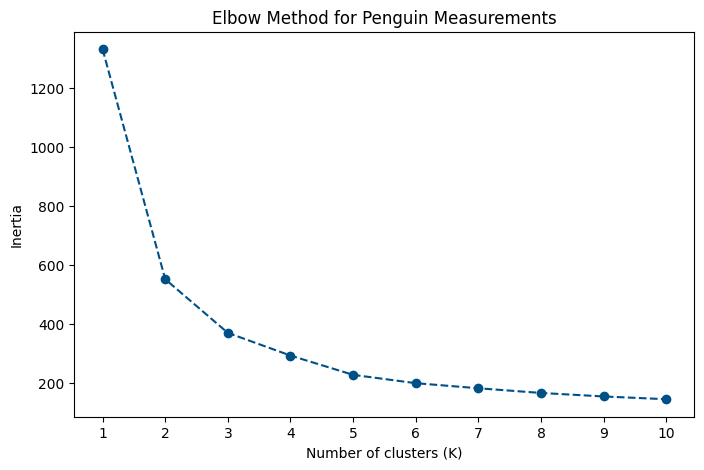

K-Means silhouette score (K=3): 0.446
Mean measurements by cluster:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
kmeans_cluster,,,,
0,38.3,18.1,188.6,3593.8
1,47.6,15.0,217.2,5092.4
2,47.7,18.7,196.9,3898.2


Species composition by cluster (row proportions):


species,Adelie,Chinstrap,Gentoo
kmeans_cluster,,,
0,0.96,0.04,0.0
1,0.00,0.00,1.0
2,0.26,0.74,0.0


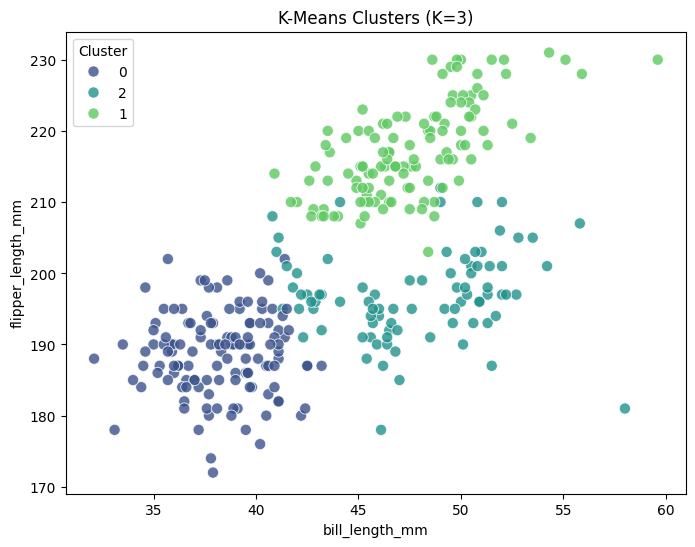

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(penguins_cont)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o', linestyle='--', color='#005088')
plt.xticks(list(k_values))
plt.title('Elbow Method for Penguin Measurements')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.show()

# The elbow is around K=3; use this reproducible choice for the baseline.
best_k = 3
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(penguins_cont)
kmeans_silhouette = silhouette_score(penguins_cont, kmeans_labels)
penguins_clean['kmeans_cluster'] = kmeans_labels

print(f'K-Means silhouette score (K={best_k}): {kmeans_silhouette:.3f}')
print('Mean measurements by cluster:')
display(penguins_clean.groupby('kmeans_cluster')[continuous_features].mean().round(1))
print('Species composition by cluster (row proportions):')
display(pd.crosstab(penguins_clean['kmeans_cluster'], penguins_clean['species'], normalize='index').round(2))

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue=penguins_clean['kmeans_cluster'].astype(str),
    palette='viridis',
    s=65,
    alpha=0.8
)
plt.title(f'K-Means Clusters (K={best_k})')
plt.legend(title='Cluster')
plt.show()

# Task 3: The Categorical variables (K-Modes)

 Group the penguins only by their categorical labels.

1. Train a KModes model using penguins_cat. Set init='Cao' so your starting centroids are placed on the most common overlaps.

2. Set your evaluation metric to Hamming distance.

3. Visualise and analyse the clusters.

K-Modes Hamming silhouette score (K=3): 0.329
Category composition by cluster (row proportions):

species


species,Adelie,Chinstrap,Gentoo
kmodes_cluster,,,
0,0.66,0.00,0.34
1,0.28,0.72,0.00
2,0.00,0.00,1.00



island


island,Biscoe,Dream,Torgersen
kmodes_cluster,,,
0,0.58,0.16,0.26
1,0.00,1.00,0.00
2,1.00,0.00,0.00



sex


sex,Female,Male
kmodes_cluster,,
0,0.26,0.74
1,0.64,0.36
2,1.00,0.00


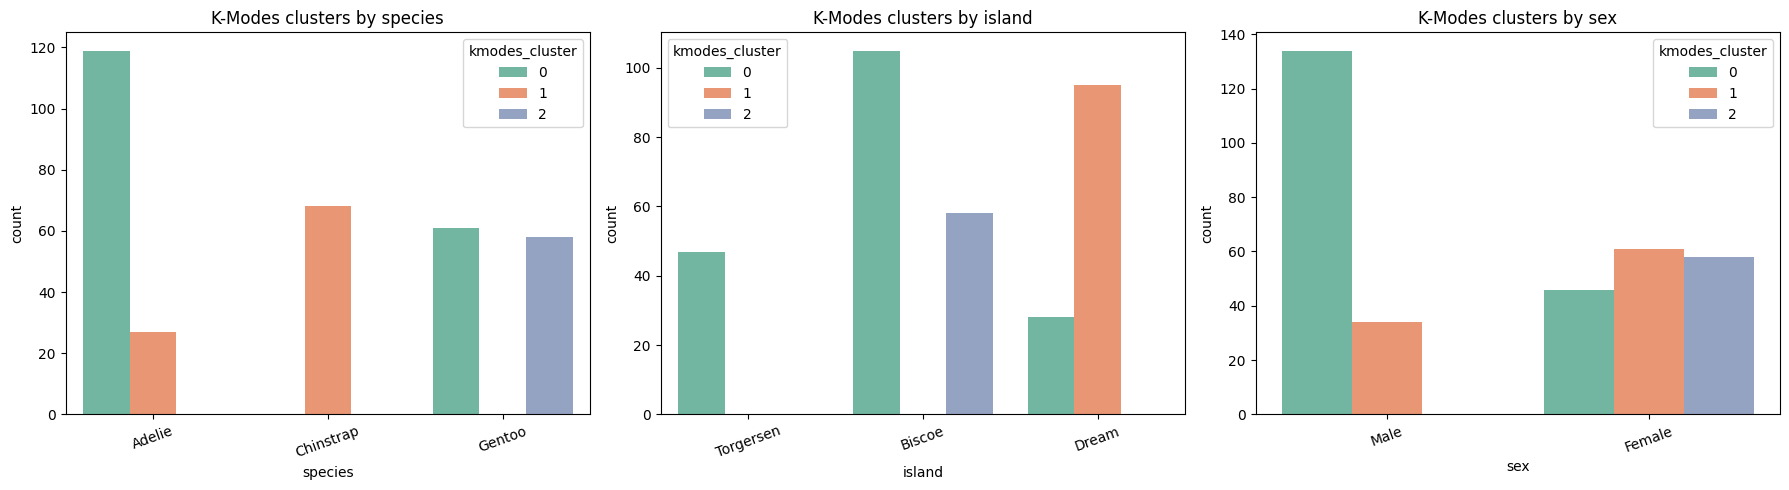

In [15]:
from kmodes.kmodes import KModes
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import silhouette_score

kmodes = KModes(n_clusters=3, init='Cao', n_init=5, random_state=42, verbose=0)
kmodes_labels = kmodes.fit_predict(penguins_cat)
penguins_clean['kmodes_cluster'] = kmodes_labels

# Encode labels only to calculate Hamming distance; the model uses the original categories.
categorical_encoded = OrdinalEncoder().fit_transform(penguins_cat)
kmodes_silhouette = silhouette_score(categorical_encoded, kmodes_labels, metric='hamming')
print(f'K-Modes Hamming silhouette score (K=3): {kmodes_silhouette:.3f}')
print('Category composition by cluster (row proportions):')
for feature in categorical_features:
    print(f'\n{feature}')
    display(pd.crosstab(penguins_clean['kmodes_cluster'], penguins_clean[feature], normalize='index').round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feature in zip(axes, categorical_features):
    sns.countplot(data=penguins_clean, x=feature, hue='kmodes_cluster', ax=ax, palette='Set2')
    ax.set_title(f'K-Modes clusters by {feature}')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

# Task 4: Combining K-Prototypes and Gower

1. Compute and save the N x N Gower distance matrix using your cleaned penguins_mixed dataset.

2. Train a KPrototypes model. Be sure to pass the integer index positions of your categorical columns so the algorithm knows when to use Euclidean or Hamming distance.

3. Evaluate the model’s Silhouette score using your precomputed Gower matrix, making sure to set metric='precomputed'.

4. Visualise and analyse the clsuters.

Gower distance matrix shape: (333, 333)
K-Prototypes Gower silhouette score (K=3): 0.465
Species composition by cluster (row proportions):


species,Adelie,Chinstrap,Gentoo
kproto_cluster,,,
0,0.00,0.00,1.0
1,0.96,0.04,0.0
2,0.25,0.75,0.0


Mean measurements by cluster:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
kproto_cluster,,,,
0,47.6,15.0,217.2,5092.4
1,38.3,18.1,188.7,3596.9
2,47.7,18.8,196.9,3897.0


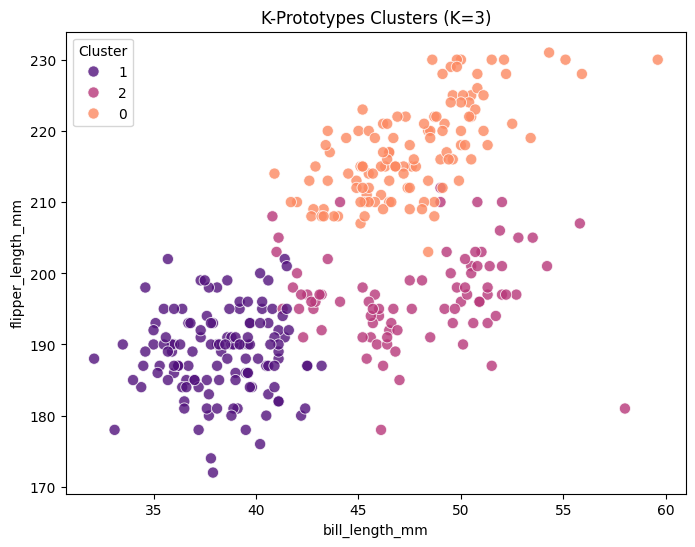

In [16]:
import gower
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score

# Gower combines scaled numeric distances with categorical mismatches.
gower_dist_matrix = gower.gower_matrix(penguins_mixed)
print(f'Gower distance matrix shape: {gower_dist_matrix.shape}')

categorical_indices = [penguins_mixed.columns.get_loc(col) for col in categorical_features]
mixed_k = 3
kprototypes = KPrototypes(n_clusters=mixed_k, init='Cao', n_init=5, random_state=42, verbose=0)
kproto_labels = kprototypes.fit_predict(penguins_mixed, categorical=categorical_indices)
penguins_clean['kproto_cluster'] = kproto_labels
kproto_silhouette = silhouette_score(gower_dist_matrix, kproto_labels, metric='precomputed')
print(f'K-Prototypes Gower silhouette score (K={mixed_k}): {kproto_silhouette:.3f}')
print('Species composition by cluster (row proportions):')
display(pd.crosstab(penguins_clean['kproto_cluster'], penguins_clean['species'], normalize='index').round(2))
print('Mean measurements by cluster:')
display(penguins_clean.groupby('kproto_cluster')[continuous_features].mean().round(1))

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue=penguins_clean['kproto_cluster'].astype(str),
    palette='magma',
    s=65,
    alpha=0.8
)
plt.title(f'K-Prototypes Clusters (K={mixed_k})')
plt.legend(title='Cluster')
plt.show()

# Task 5: Hierarchical Segregation (Agglomerative Clustering)

Let's see whether a bottom-up density method yields different biological groupings than the top-down K-Prototypes method.

1. Train an AgglomerativeClustering model with the same K value you used for K-Prototypes.

2. Be careful: if you use scikit-learn's default settings, it will use Euclidean distance on your Gower distances, which will ruin the model. Make sure to set metric='precomputed' and linkage='average'.

3. Compare the Gower Silhouette score from this method to the one from K-Prototypes. Which method fits the penguin dataset better?

4. Visualise and analyse the clsuters.

,Model,Gower silhouette
0,K-Prototypes,0.465
1,Agglomerative (average linkage),0.556


Agglomerative clustering has the higher Gower silhouette on this run.
Species composition by agglomerative cluster (row proportions):


species,Adelie,Chinstrap,Gentoo
agglomerative_cluster,,,
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,0.0,1.0,0.0


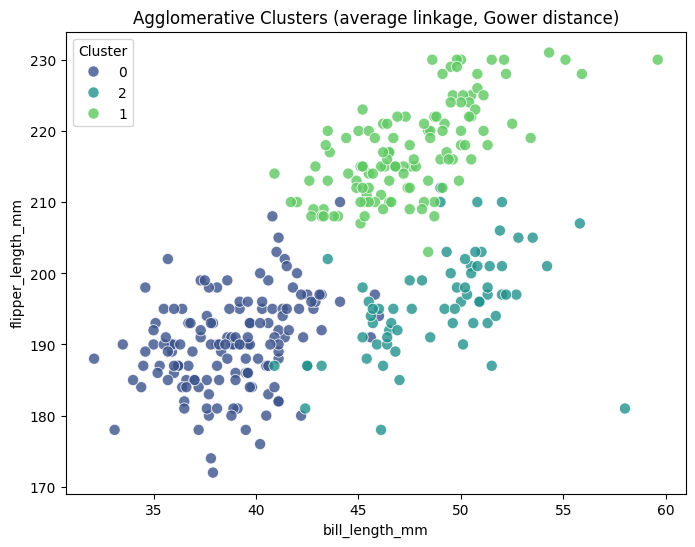

In [17]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

agg_clustering = AgglomerativeClustering(
    n_clusters=mixed_k,
    metric='precomputed',
    linkage='average'
)
agg_labels = agg_clustering.fit_predict(gower_dist_matrix)
penguins_clean['agglomerative_cluster'] = agg_labels
agg_silhouette = silhouette_score(gower_dist_matrix, agg_labels, metric='precomputed')

comparison = pd.DataFrame({
    'Model': ['K-Prototypes', 'Agglomerative (average linkage)'],
    'Gower silhouette': [kproto_silhouette, agg_silhouette]
})
display(comparison.round(3))
if agg_silhouette > kproto_silhouette:
    print('Agglomerative clustering has the higher Gower silhouette on this run.')
else:
    print('K-Prototypes has the higher Gower silhouette on this run.')

print('Species composition by agglomerative cluster (row proportions):')
display(pd.crosstab(penguins_clean['agglomerative_cluster'], penguins_clean['species'], normalize='index').round(2))

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue=penguins_clean['agglomerative_cluster'].astype(str),
    palette='viridis',
    s=65,
    alpha=0.8
)
plt.title('Agglomerative Clusters (average linkage, Gower distance)')
plt.legend(title='Cluster')
plt.show()

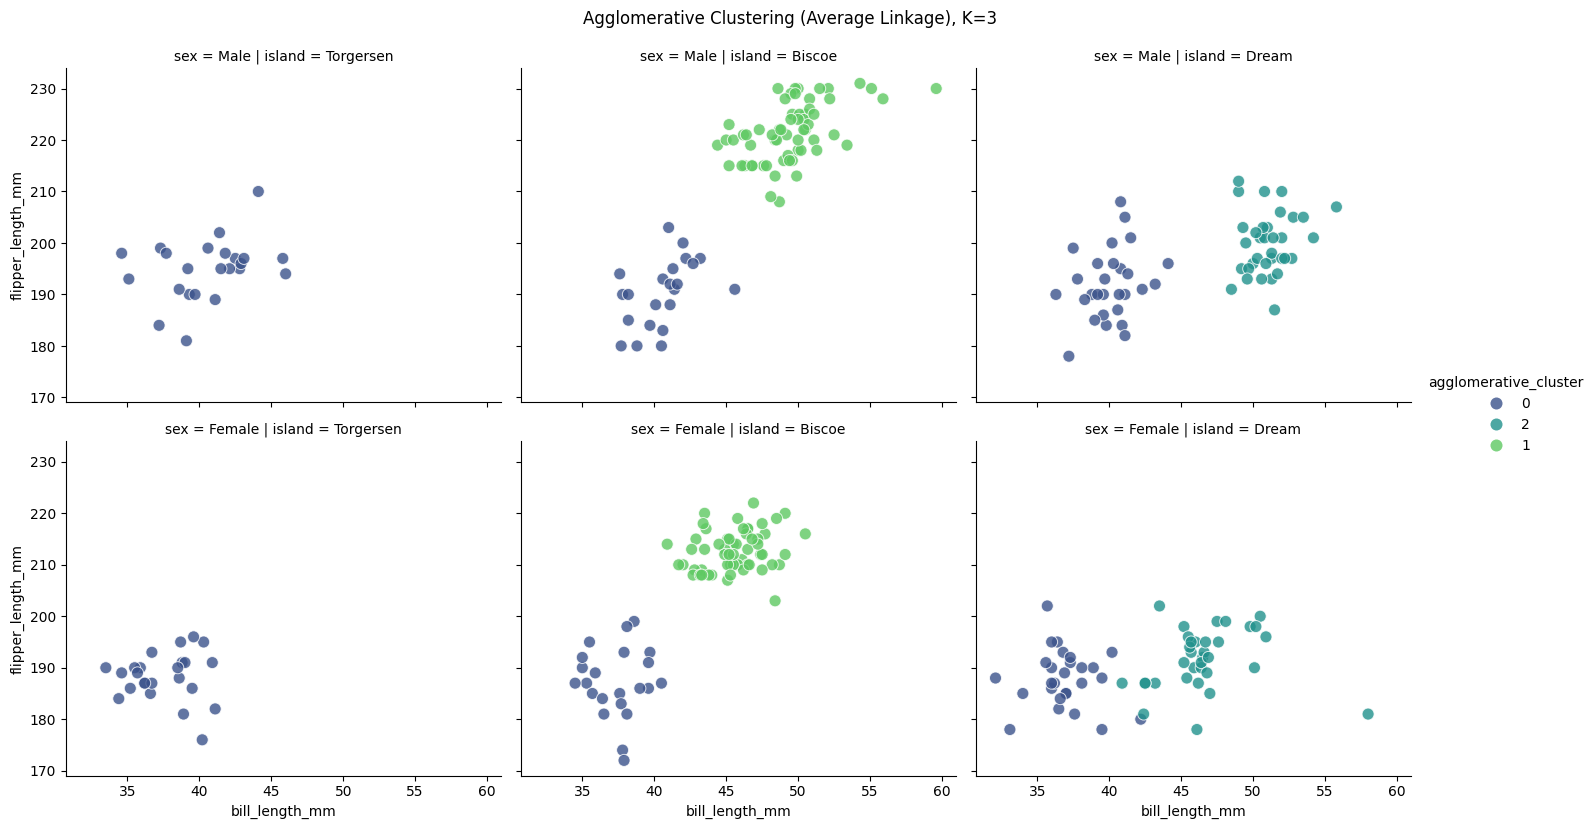

In [19]:
g = sns.relplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue=penguins_clean['agglomerative_cluster'].astype(str),
    col='island',
    row='sex',
    palette='viridis',
    s=75,
    alpha=0.8,
    height=4,
    aspect=1.2
)

g.fig.suptitle(
    f'Agglomerative Clustering (Average Linkage), K={mixed_k}',
    y=1.03
)
plt.show()

# Task 6: Density and Outliers (DBSCAN)

Now we'll use density to find the main penguin profiles and clearly identify the unusual outliers.

1. Train a DBSCAN model. Use the Gower matrix and set the metric='precomputed'.
2. In Gower space, distances go up to 1.0. If you use the default eps=0.5 in scikit-learn, the algorithm will group penguins that are 50% different, putting them all into one big cluster.
3. You need to carefully adjust eps (try starting at 0.10 to 0.20) and min_samples until the algorithm splits the penguins into several clear clusters.
4. How many penguins did your adjusted model mark as pure noise (-1)?
5. Visualise and analyse the clusters and the outliers.

,eps,min_samples,clusters,noise_points,silhouette
0,0.10,10,10,0,0.735498
1,0.10,20,10,0,0.735498
2,0.10,25,6,91,0.762026
3,0.10,30,4,146,0.772071
4,0.10,40,2,214,0.782045
5,0.12,10,10,0,0.735498
6,0.12,20,10,0,0.735498
7,0.12,25,6,91,0.762026
8,0.12,30,4,146,0.772071
9,0.12,40,2,214,0.782045


DBSCAN found 3 clusters and marked 5 penguins as noise (-1).
Species composition by DBSCAN cluster (row proportions; noise included):


species,Adelie,Chinstrap,Gentoo
dbscan_cluster,,,
-1,1.0,0.0,0.0
0,1.0,0.0,0.0
1,0.0,1.0,0.0
2,0.0,0.0,1.0


Gower silhouette excluding noise: 0.561


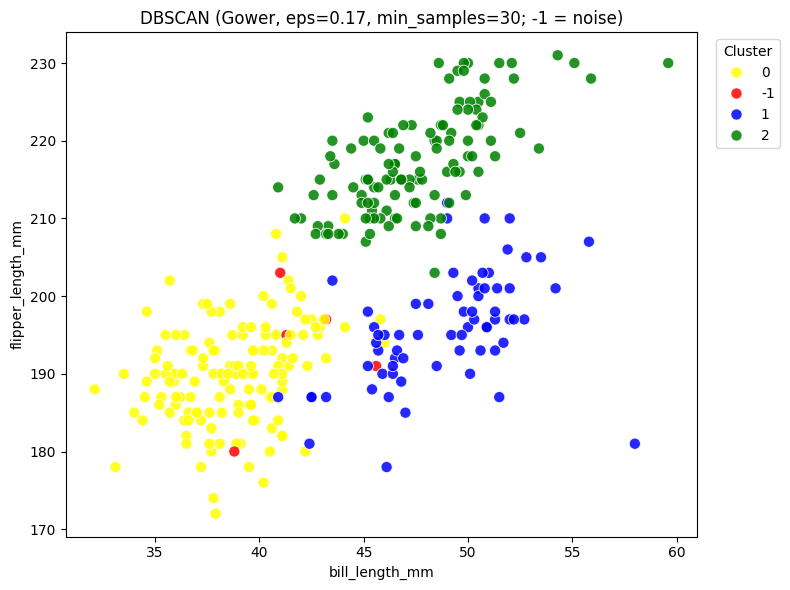

In [26]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

dbscan_palette = {'-1': 'red', '0': 'yellow', '1': 'blue', '2': 'green'}

dbscan_trials = []
for eps in [0.10, 0.12, 0.15, 0.17, 0.18, 0.20]:
    for min_samples in [10, 20, 25, 30, 40]:
        trial_labels = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed').fit_predict(gower_dist_matrix)
        n_clusters = len(set(trial_labels) - {-1})
        dbscan_trials.append({
            'eps': eps,
            'min_samples': min_samples,
            'clusters': n_clusters,
            'noise_points': int(np.sum(trial_labels == -1)),
            'silhouette': silhouette_score(
                gower_dist_matrix[trial_labels != -1][:, trial_labels != -1],
                trial_labels[trial_labels != -1],
                metric='precomputed'
            ) if n_clusters >= 2 else None
        })
display(pd.DataFrame(dbscan_trials))

dbscan_eps = 0.17
dbscan_min_samples = 30
dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples, metric='precomputed')
dbscan_labels = dbscan.fit_predict(gower_dist_matrix)
penguins_clean['dbscan_cluster'] = dbscan_labels
noise_count = int(np.sum(dbscan_labels == -1))
cluster_count = len(set(dbscan_labels) - {-1})
print(f'DBSCAN found {cluster_count} clusters and marked {noise_count} penguins as noise (-1).')
print('Species composition by DBSCAN cluster (row proportions; noise included):')
display(pd.crosstab(penguins_clean['dbscan_cluster'], penguins_clean['species'], normalize='index').round(2))

if cluster_count >= 2:
    non_noise = dbscan_labels != -1
    dbscan_silhouette = silhouette_score(
        gower_dist_matrix[non_noise][:, non_noise],
        dbscan_labels[non_noise],
        metric='precomputed'
    )
    print(f'Gower silhouette excluding noise: {dbscan_silhouette:.3f}')

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue=penguins_clean['dbscan_cluster'].astype(str),
    palette=dbscan_palette,
    s=65,
    alpha=0.85
)
plt.title(f'DBSCAN (Gower, eps={dbscan_eps}, min_samples={dbscan_min_samples}; -1 = noise)')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()